# ANN Index Robustness under Query Corruption

How do the four ANN indexes of the main benchmark - **IVF-Flat, IVF-PQ, HNSW,
HNSW-PQ** - behave when the *query image* is corrupted while the gallery stays
clean? This notebook analyses the outputs of
`pipeline/index_robustness.py`, which reuses the corrupted queries cached by
`pipeline/corruption.py` (unchanged) and rebuilds every index with the main
benchmark's construction parameters at the knee-score setting of its
full-vector partner (IVF-Flat/IVF-PQ share `nprobe`, HNSW/HNSW-PQ share
`efSearch`).

Three metric families per query variant, at K = 5/10/20 (plots show K = 10):

| Family | Ground truth | Actual | Isolates |
|---|---|---|---|
| `fidelity_*` | exact search of the **same corrupted** query | ANN on the corrupted query | pure ANN approximation error under corruption |
| `end_to_end_*` | exact search of the **clean** query | ANN on the corrupted query | total retrieval degradation (model + index) |
| `stability_*` | the **same index** on the clean query | ANN on the corrupted query | how much the index's own output changes |

The `original` level (uncorrupted query) anchors the sanity checks: stability
is exactly 1.0 by construction, and fidelity equals end-to-end. The exact
end-to-end reference of Section 8 of `compare_methods.ipynb` is overlaid on
the end-to-end plots, so the gap between each curve and it is the *additional*
loss caused by the index.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Find this experiment folder whether the notebook runs from its own
# folder or from the repository root, then reuse the shared registry.
EXPERIMENT_DIR = Path.cwd()
if not (EXPERIMENT_DIR / "datasets.py").exists():
    EXPERIMENT_DIR = Path.cwd() / "experiments" / "ann-comparison"
sys.path.insert(0, str(EXPERIMENT_DIR))
from datasets import CONFIGS, results_dir

# Level order within each transform, from the corruption sweep definition.
sys.path.insert(0, str(EXPERIMENT_DIR / "pipeline"))
from perturbations import TRANSFORMS

CONFIG_KEYS = [k for k in ["vit-coco", "resnet-coco", "vit-zappos", "resnet-zappos"]
               if (results_dir(k) / "index_robustness" / "index_robustness_summary.csv").exists()]
TRANSFORM_ORDER = [spec["name"] for spec in TRANSFORMS]
K_SHOW = 10   # K used in every plot
ALGORITHMS = ["IVF-Flat", "IVF-PQ", "HNSW", "HNSW-PQ"]
ALGO_STYLE = {
    "IVF-Flat": {"color": "tab:blue", "linestyle": "-"},
    "IVF-PQ": {"color": "tab:cyan", "linestyle": "-"},
    "HNSW": {"color": "tab:orange", "linestyle": "--"},
    "HNSW-PQ": {"color": "tab:red", "linestyle": "--"},
}

if not CONFIG_KEYS:
    raise SystemExit(
        "No index-robustness results. Run, from the repository root:\n"
        "  python experiments/ann-comparison/pipeline/corruption.py --config all\n"
        "  python experiments/ann-comparison/pipeline/index_robustness.py --config all"
    )

summary = pd.concat(
    [pd.read_csv(results_dir(key) / "index_robustness" / "index_robustness_summary.csv",
                 keep_default_na=False)
     for key in CONFIG_KEYS], ignore_index=True)

# The exact end-to-end reference (clean-query neighbours, exact search),
# i.e. the corruption experiment of compare_methods.ipynb Section 8.
exact_path = EXPERIMENT_DIR / "results" / "robustness_corruption_combined.csv"
exact = pd.read_csv(exact_path, keep_default_na=False) if exact_path.exists() else None

def level_key(transform, level):
    """(transform index, level index) in the sweep's own order."""
    if transform == "original":
        return (-1, 0)
    for t, spec in enumerate(TRANSFORMS):
        if spec["name"] == transform:
            for l, value in enumerate(spec["values"]):
                if float(level) == float(value):
                    return (t, l)
    return (len(TRANSFORMS), 0)

summary["order"] = [level_key(t, l)
                    for t, l in zip(summary["transform"], summary["level"])]

print("Configurations:", " | ".join(CONFIGS[k]["label"] for k in CONFIG_KEYS))
print(f"{len(summary)} summary rows | K shown: {K_SHOW}")
for key in CONFIG_KEYS:
    params = json.loads((results_dir(key) / "index_robustness" / "index_robustness_params.json").read_text())
    print(f"{CONFIGS[key]['label']:<20} {params['num_queries']} queries x "
          f"{params['variants_per_query']} variants | {params['gallery_size']:,} gallery | "
          f"faiss {params['faiss_version']} | split: {params['split_source']}")

Configurations: ViT-B/16 / COCO | ResNet18 / COCO | ViT-B/16 / Zappos | ResNet18 / Zappos
544 summary rows | K shown: 10
ViT-B/16 / COCO      200 queries x 34 variants | 122,403 gallery | faiss 1.15.0 | split: reproduced from ann_results.json (seed 42)
ResNet18 / COCO      200 queries x 34 variants | 122,403 gallery | faiss 1.15.0 | split: reproduced from ann_results.json (seed 42)
ViT-B/16 / Zappos    200 queries x 34 variants | 49,025 gallery | faiss 1.15.0 | split: reproduced from ann_results.json (seed 42)
ResNet18 / Zappos    200 queries x 34 variants | 49,025 gallery | faiss 1.15.0 | split: reproduced from ann_results.json (seed 42)


## 1. Settings and original-level self-checks

Every configuration runs each index at its partner's knee setting. On the
`original` level the two exact references agree, so fidelity = end-to-end,
and stability is exactly 1.0 (the index is compared with itself).

In [2]:
overview = []
for key in CONFIG_KEYS:
    rows = summary[summary["config"] == key]
    for algorithm in ALGORITHMS:
        algo = rows[rows["algorithm"] == algorithm]
        original = algo[algo["transform"] == "original"].iloc[0]
        overview.append({
            "config": key,
            "algorithm": algorithm,
            "setting": original["setting"],
            "index_mb": round(float(original["index_size_mb"]), 1),
            "ms/variant": original["latency_ms_per_variant"],
            f"fidelity R@{K_SHOW}": round(original[f"fidelity_recall_at_{K_SHOW}_mean"], 4),
            f"end_to_end R@{K_SHOW}": round(original[f"end_to_end_recall_at_{K_SHOW}_mean"], 4),
            f"stability R@{K_SHOW}": round(original[f"stability_recall_at_{K_SHOW}_mean"], 4),
        })
overview = pd.DataFrame(overview)
display(overview)

for key in CONFIG_KEYS:
    original = summary[(summary["config"] == key) & (summary["transform"] == "original")]
    for algorithm in ALGORITHMS:
        row = original[original["algorithm"] == algorithm].iloc[0]
        assert row[f"stability_recall_at_{K_SHOW}_mean"] == 1.0, (key, algorithm)
    gap = (original[f"fidelity_recall_at_{K_SHOW}_mean"]
           - original[f"end_to_end_recall_at_{K_SHOW}_mean"]).abs().max()
    print(f"{CONFIGS[key]['label']:<20} original: stability == 1.0 ok | "
          f"|fidelity - end_to_end| <= {gap:.4f}")

,config,algorithm,setting,index_mb,ms/variant,fidelity R@10,end_to_end R@10,stability R@10
0,vit-coco,IVF-Flat,nprobe=4,360.3,0.3045,0.9345,0.9345,1.0
1,vit-coco,IVF-PQ,nprobe=4,8.0,0.1622,0.4795,0.4795,1.0
2,vit-coco,HNSW,efSearch=64,390.4,0.3202,0.9905,0.9905,1.0
3,vit-coco,HNSW-PQ,efSearch=64,38.1,0.1349,0.1945,0.1945,1.0
4,resnet-coco,IVF-Flat,nprobe=8,240.5,0.4258,0.9275,0.9270,1.0
5,resnet-coco,IVF-PQ,nprobe=8,5.7,0.1590,0.3440,0.3440,1.0
6,resnet-coco,HNSW,efSearch=64,270.8,0.3562,0.9885,0.9880,1.0
7,resnet-coco,HNSW-PQ,efSearch=64,36.0,0.1136,0.3680,0.3680,1.0
8,vit-zappos,IVF-Flat,nprobe=8,144.8,0.2613,0.9520,0.9520,1.0
9,vit-zappos,IVF-PQ,nprobe=8,4.1,0.1689,0.4800,0.4800,1.0


ViT-B/16 / COCO      original: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ResNet18 / COCO      original: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0005
ViT-B/16 / Zappos    original: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ResNet18 / Zappos    original: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0015


## 2. ANN fidelity under corruption

`fidelity` compares each index's answer on the corrupted query with the exact
answer *for that same corrupted query* - the model's own degradation is
removed, so what remains is the approximation error of the index itself. If
corruption did not hurt the index, every curve would stay flat at its
original-level value.

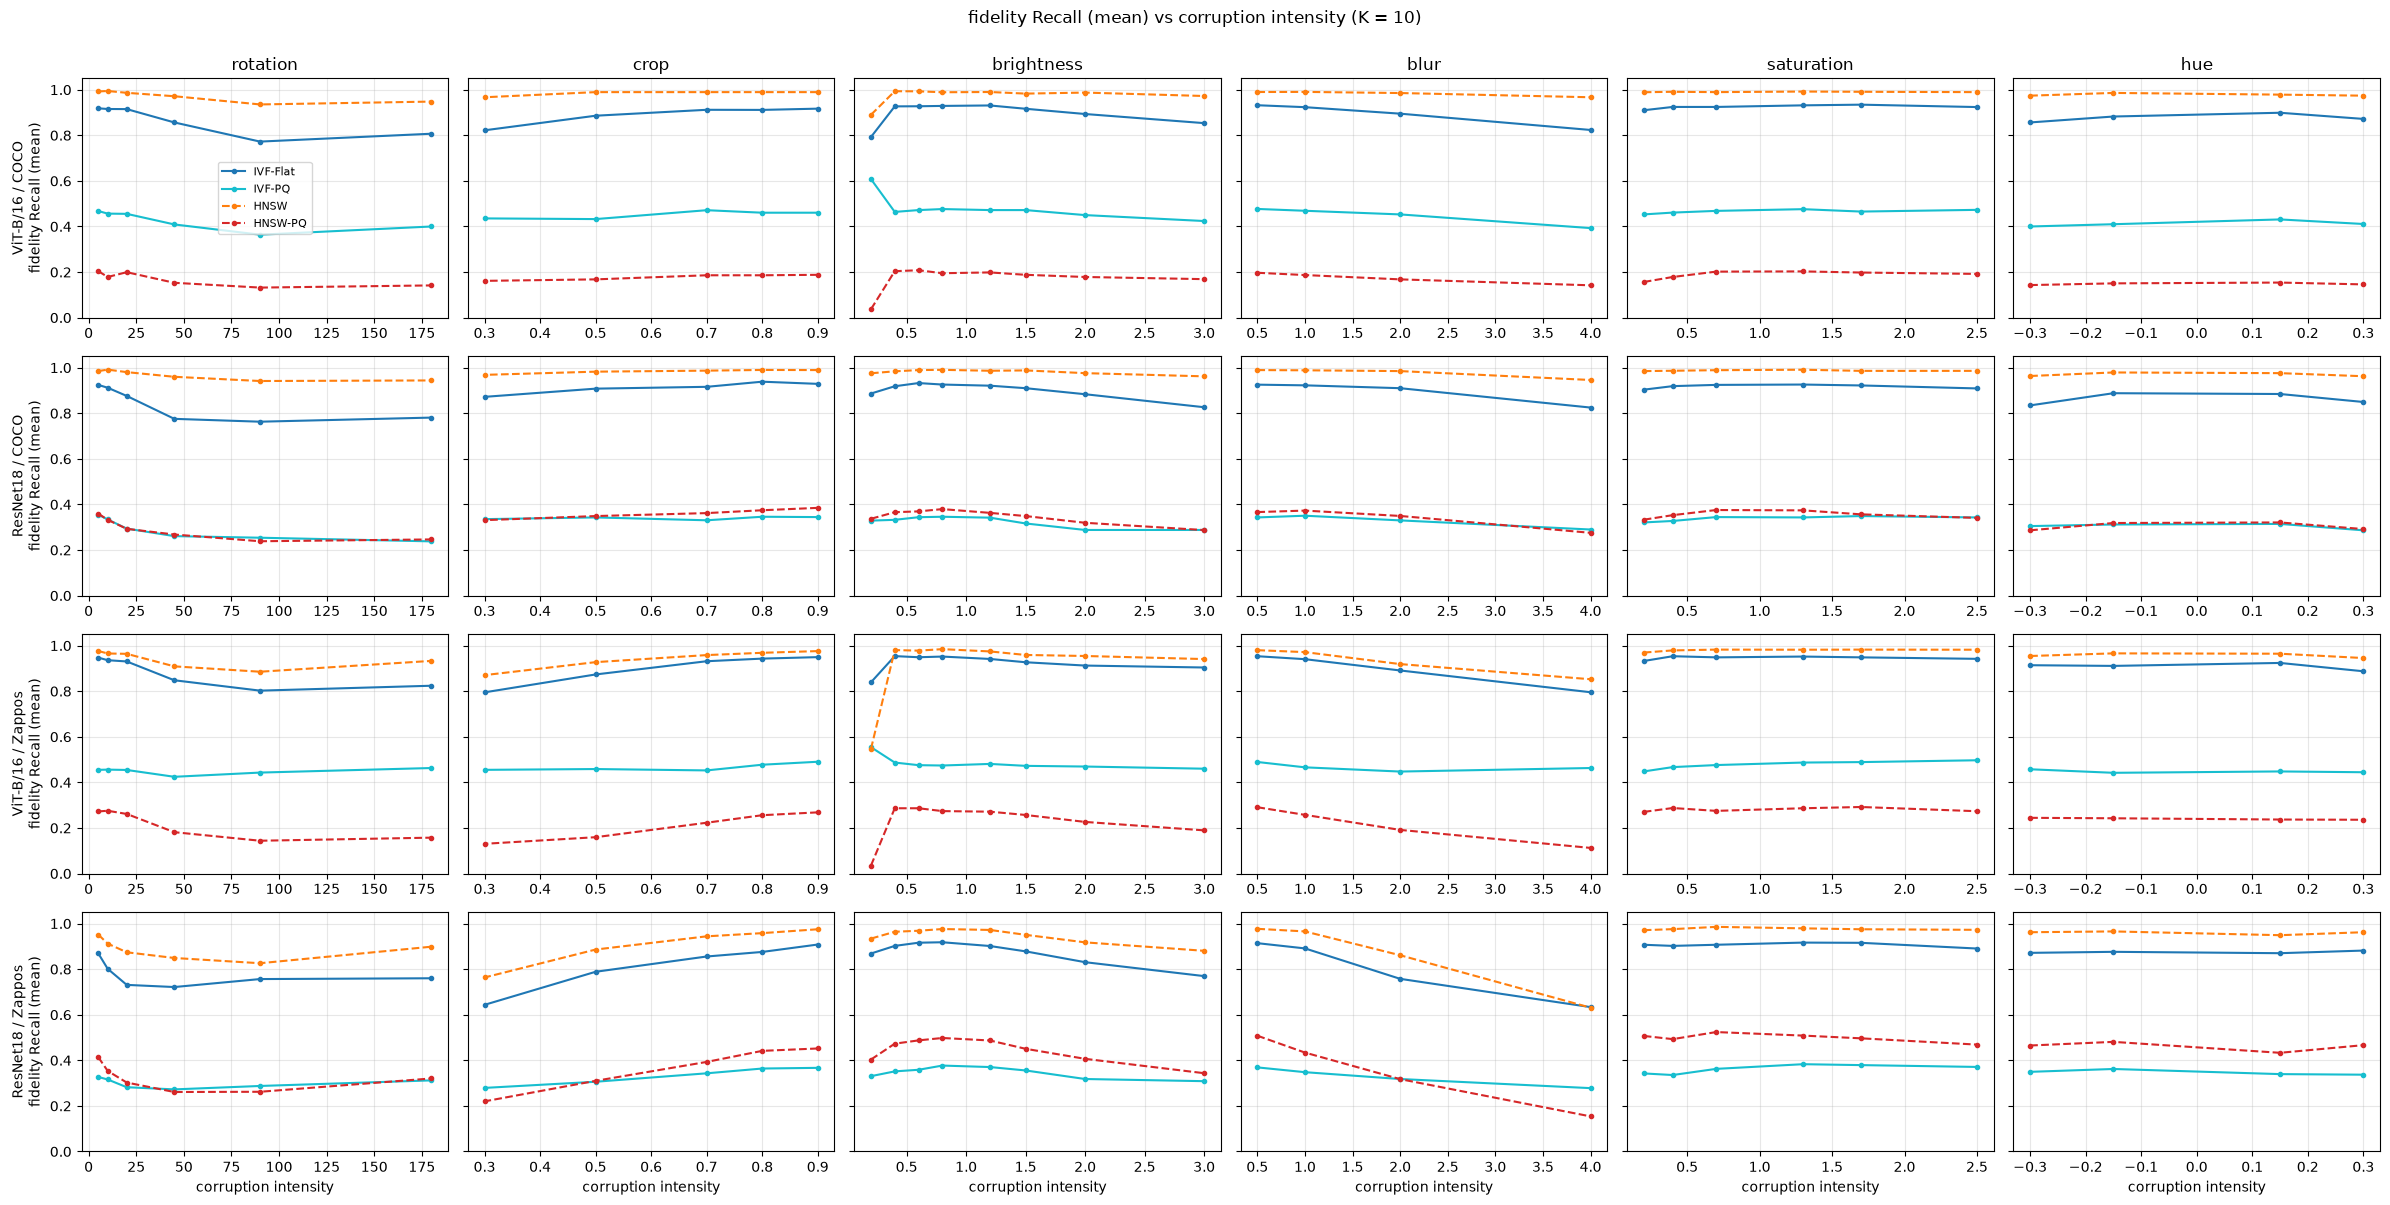

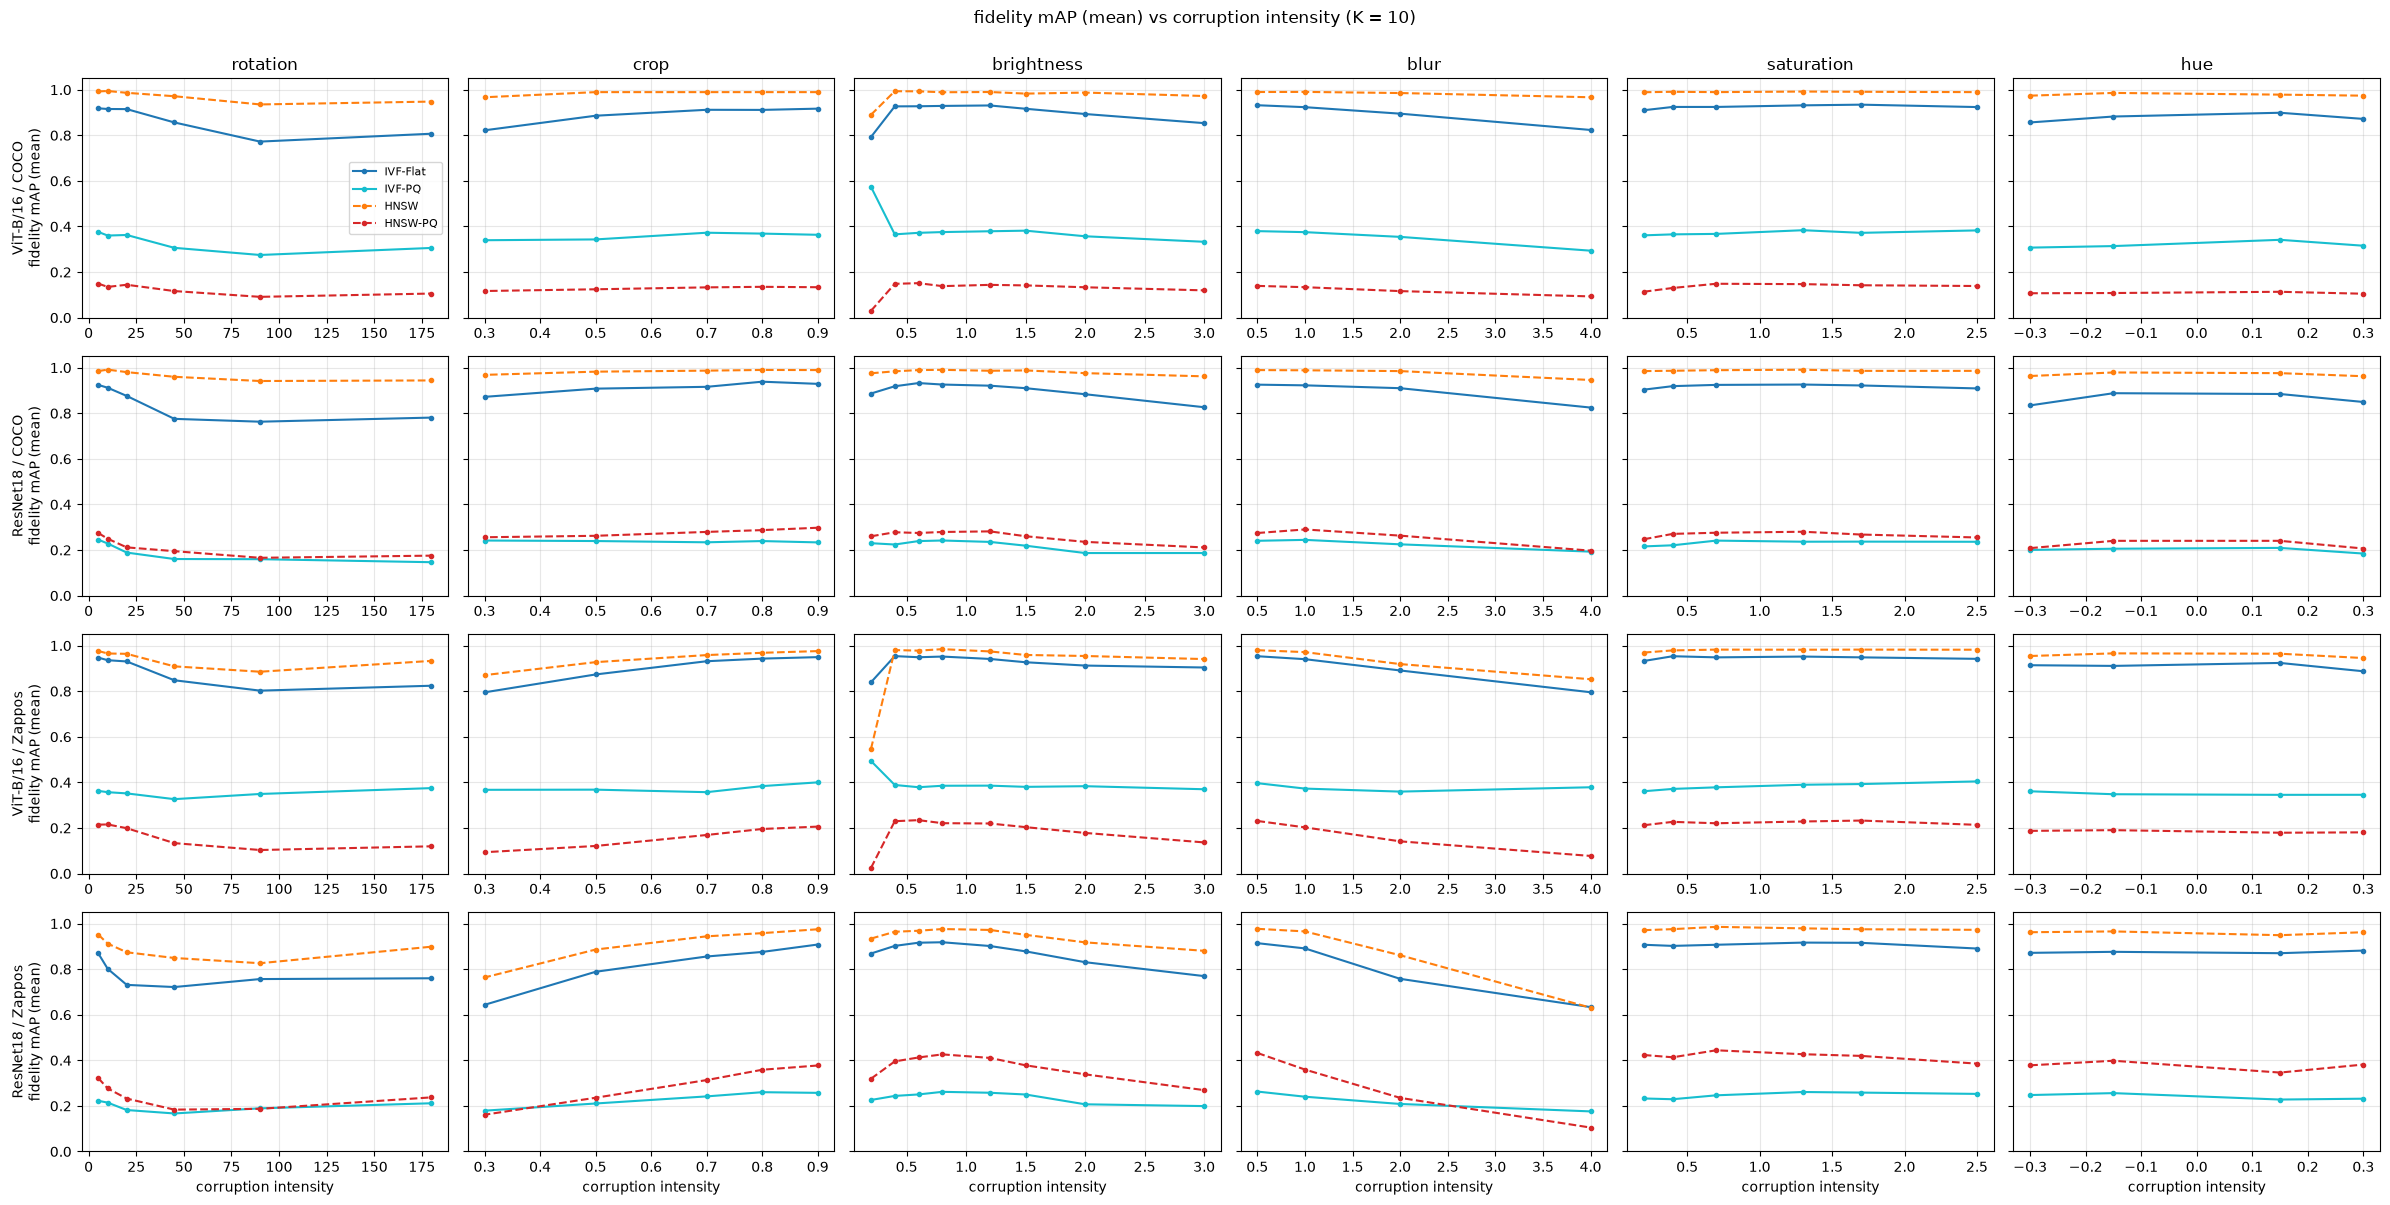

In [3]:
def corruption_grid(column, ylabel, overlay_exact=False, ylim=(0.0, 1.05)):
    """One row per configuration, one panel per transform, one line per index."""
    fig, axes = plt.subplots(len(CONFIG_KEYS), len(TRANSFORM_ORDER),
                             figsize=(4 * len(TRANSFORM_ORDER), 3 * len(CONFIG_KEYS)),
                             squeeze=False, sharey=True)
    for r, key in enumerate(CONFIG_KEYS):
        rows = summary[summary["config"] == key]
        for c, transform in enumerate(TRANSFORM_ORDER):
            ax = axes[r][c]
            sub = rows[rows["transform"] == transform].sort_values("order")
            for algorithm in ALGORITHMS:
                algo = sub[sub["algorithm"] == algorithm]
                ax.plot(algo["level"].astype(float), algo[column],
                        marker="o", markersize=3, label=algorithm, **ALGO_STYLE[algorithm])
            if overlay_exact and exact is not None:
                ref = exact[(exact["config"] == key) & (exact["transform"] == transform)]
                ref = ref.assign(order=[level_key(transform, l) for l in ref["level"]]
                                 ).sort_values("order")
                ax.plot(ref["level"].astype(float), ref[f"recall_at_{K_SHOW}_mean"],
                        color="black", linestyle=":", marker="s", markersize=3,
                        label="Exact (end-to-end)")
            if r == 0:
                ax.set_title(transform)
            if c == 0:
                ax.set_ylabel(f"{CONFIGS[key]['label']}\n{ylabel}")
            if r == len(CONFIG_KEYS) - 1:
                ax.set_xlabel("corruption intensity")
            ax.set_ylim(*ylim)
            ax.grid(alpha=0.3)
    axes[0][0].legend(fontsize=8)
    fig.suptitle(f"{ylabel} vs corruption intensity (K = {K_SHOW})", y=1.0)
    plt.tight_layout()
    plt.show()

corruption_grid(f"fidelity_recall_at_{K_SHOW}_mean", "fidelity Recall (mean)")
corruption_grid(f"fidelity_map_at_{K_SHOW}_mean", "fidelity mAP (mean)")

## 3. End-to-end retrieval quality

`end_to_end` compares each index's answer on the corrupted query with the
exact neighbours of the **clean** query - what the user actually experiences.
The dotted black line is exact search on the corrupted query (the Section 8
corruption experiment): the vertical gap to an index's curve is the additional
loss caused by the index, the rest is the model's own loss.

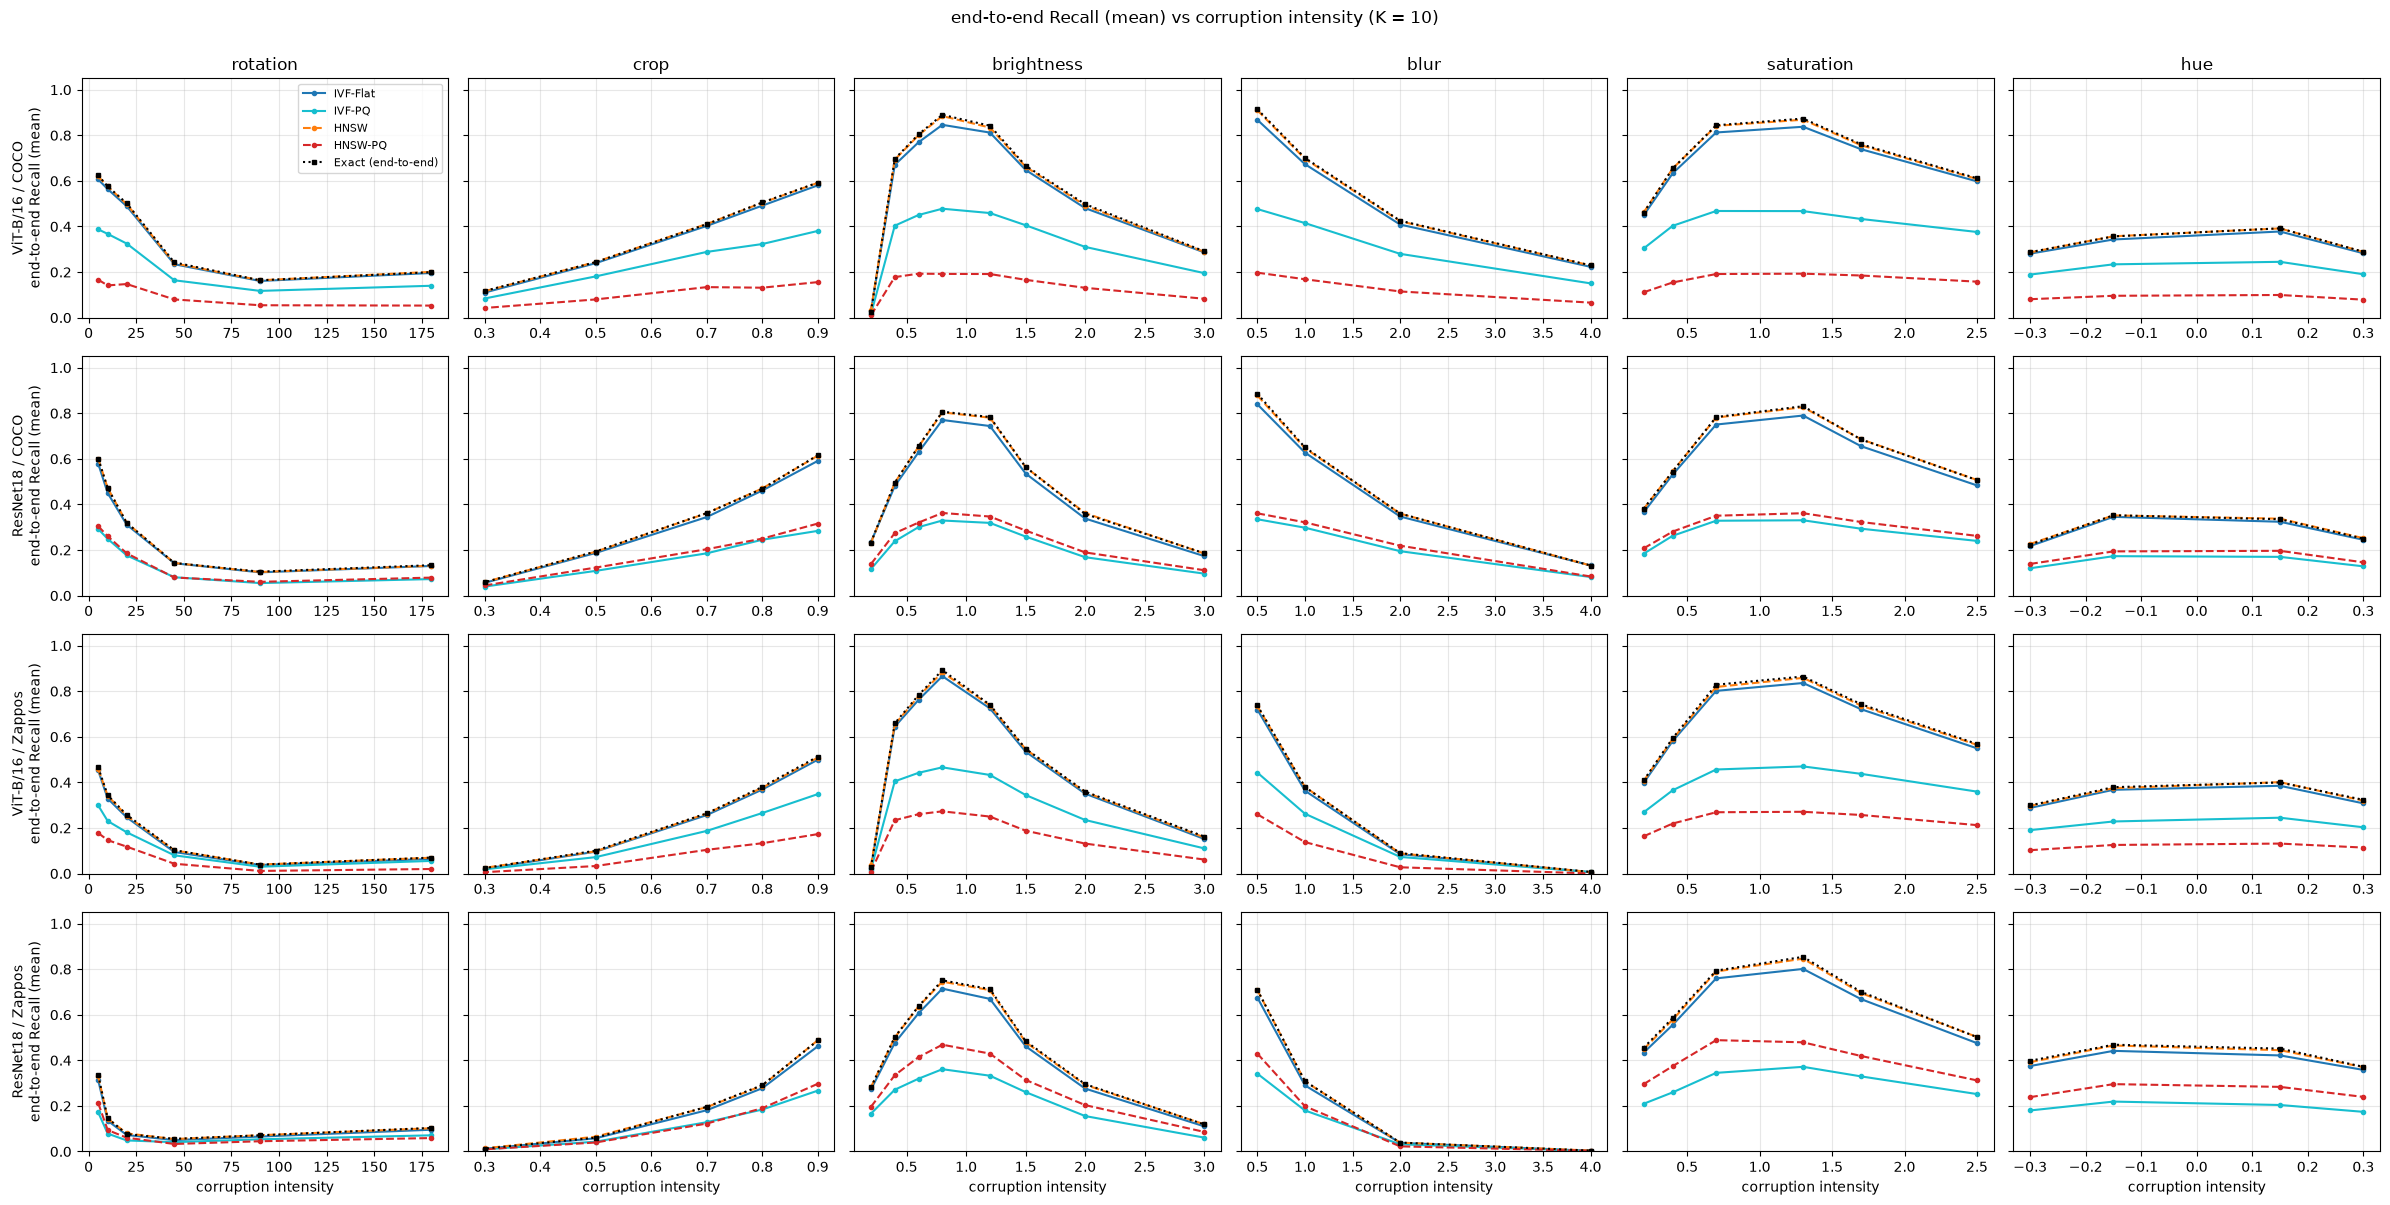

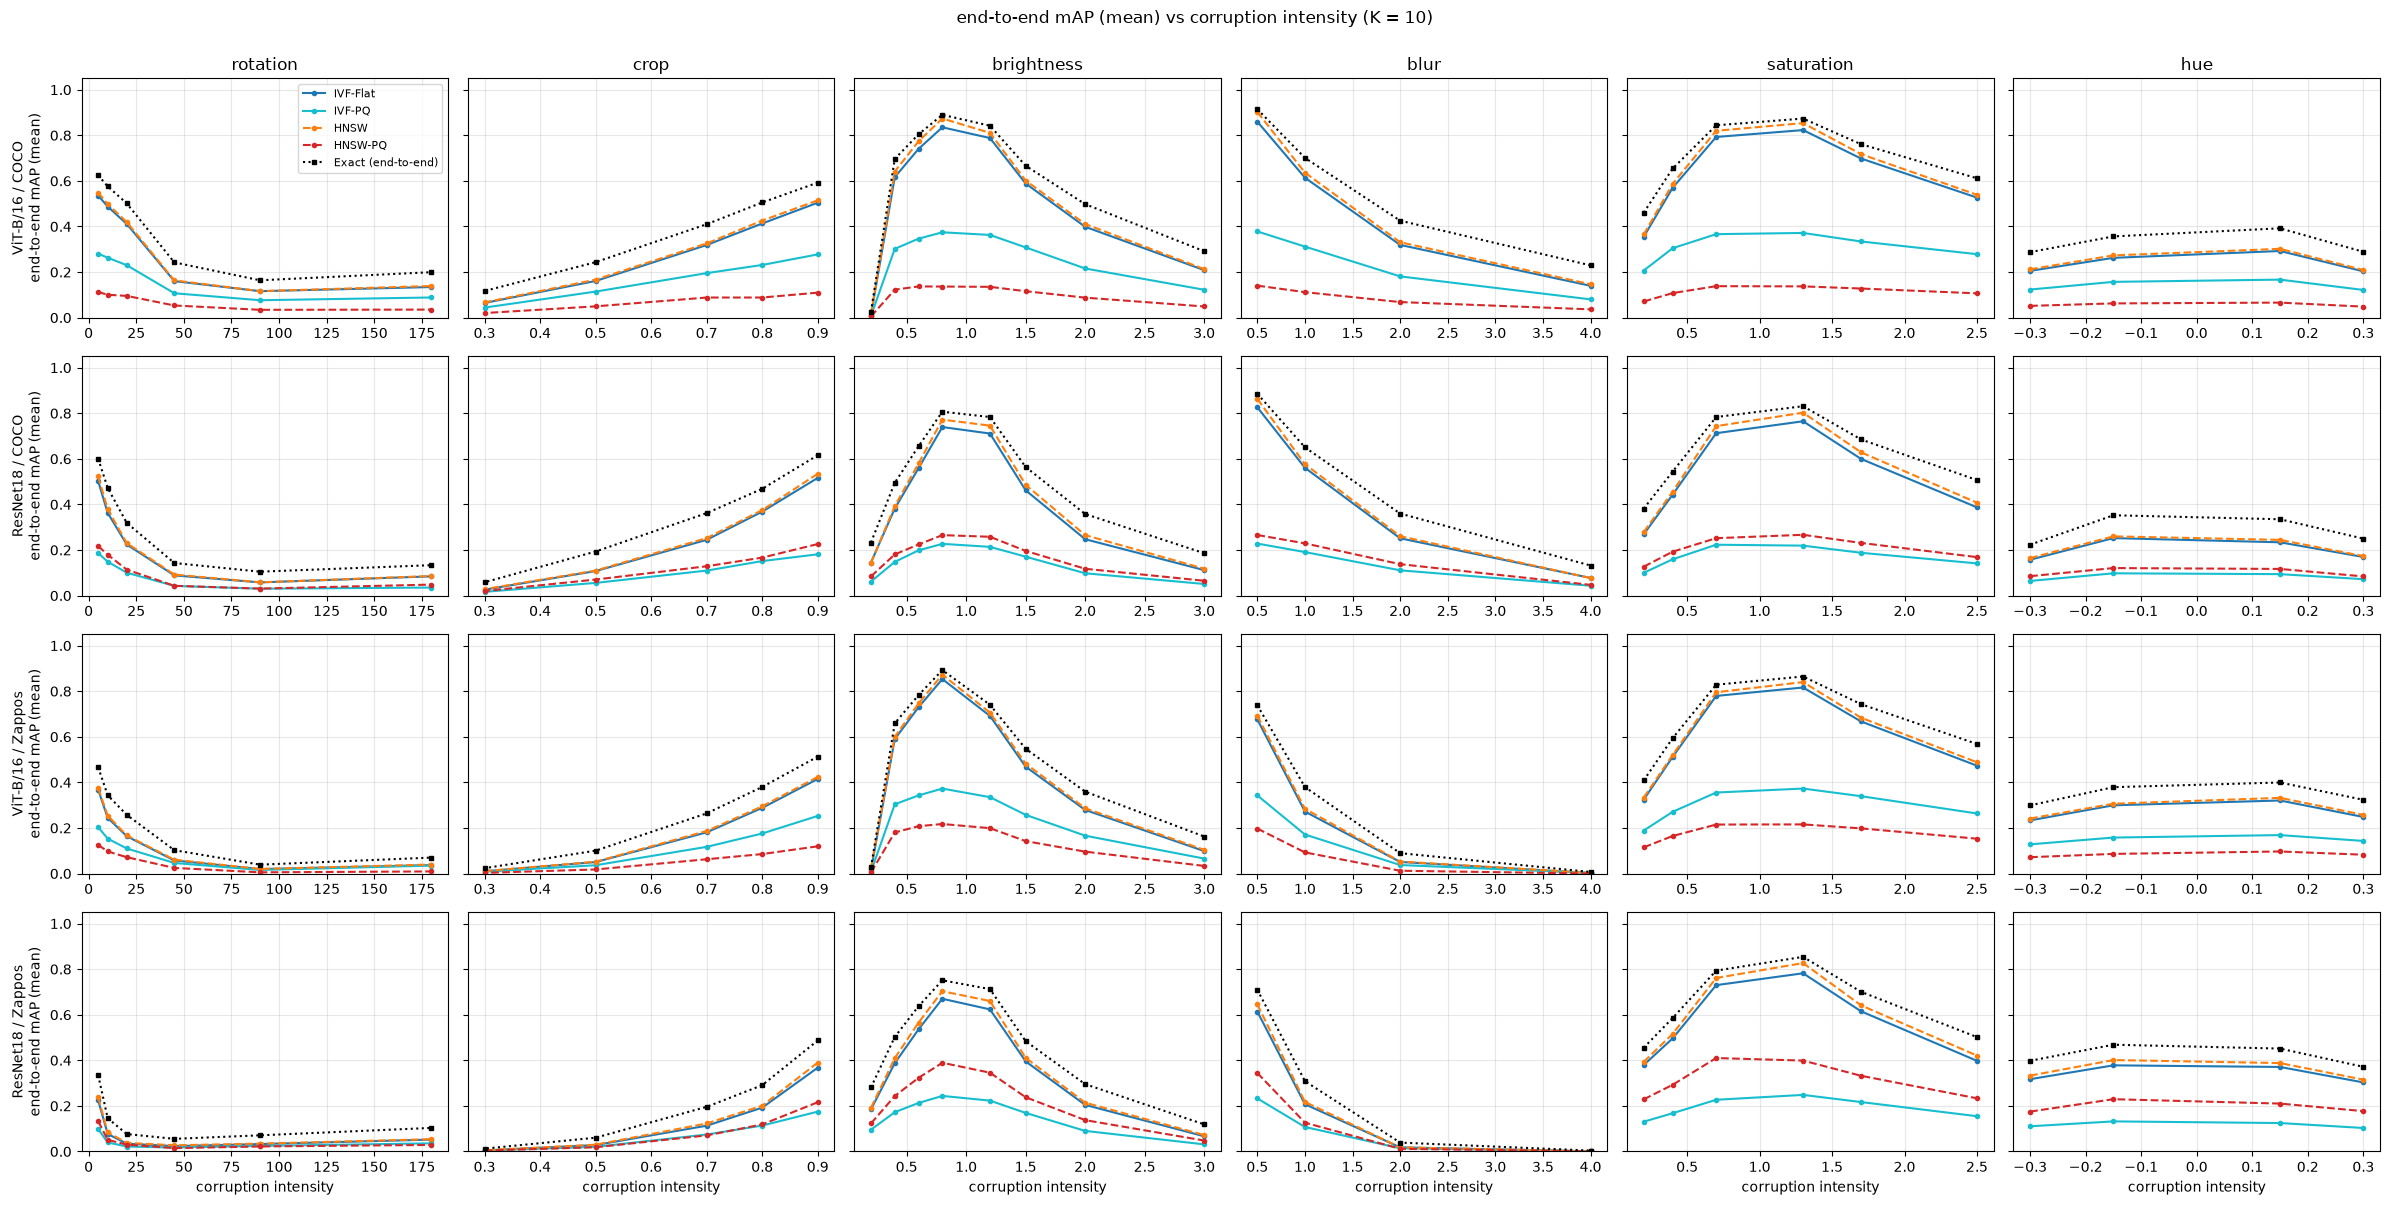

In [4]:
corruption_grid(f"end_to_end_recall_at_{K_SHOW}_mean",
                "end-to-end Recall (mean)", overlay_exact=True)
corruption_grid(f"end_to_end_map_at_{K_SHOW}_mean",
                "end-to-end mAP (mean)", overlay_exact=True)

## 4. Same-index output stability

`stability` compares each index's answer on the corrupted query with the same
index's answer on the clean query - 1.0 means the corruption did not change
the index's output at all. Unlike fidelity, this can drop even when the exact
answer also moves: it measures the index's reaction, not its correctness.

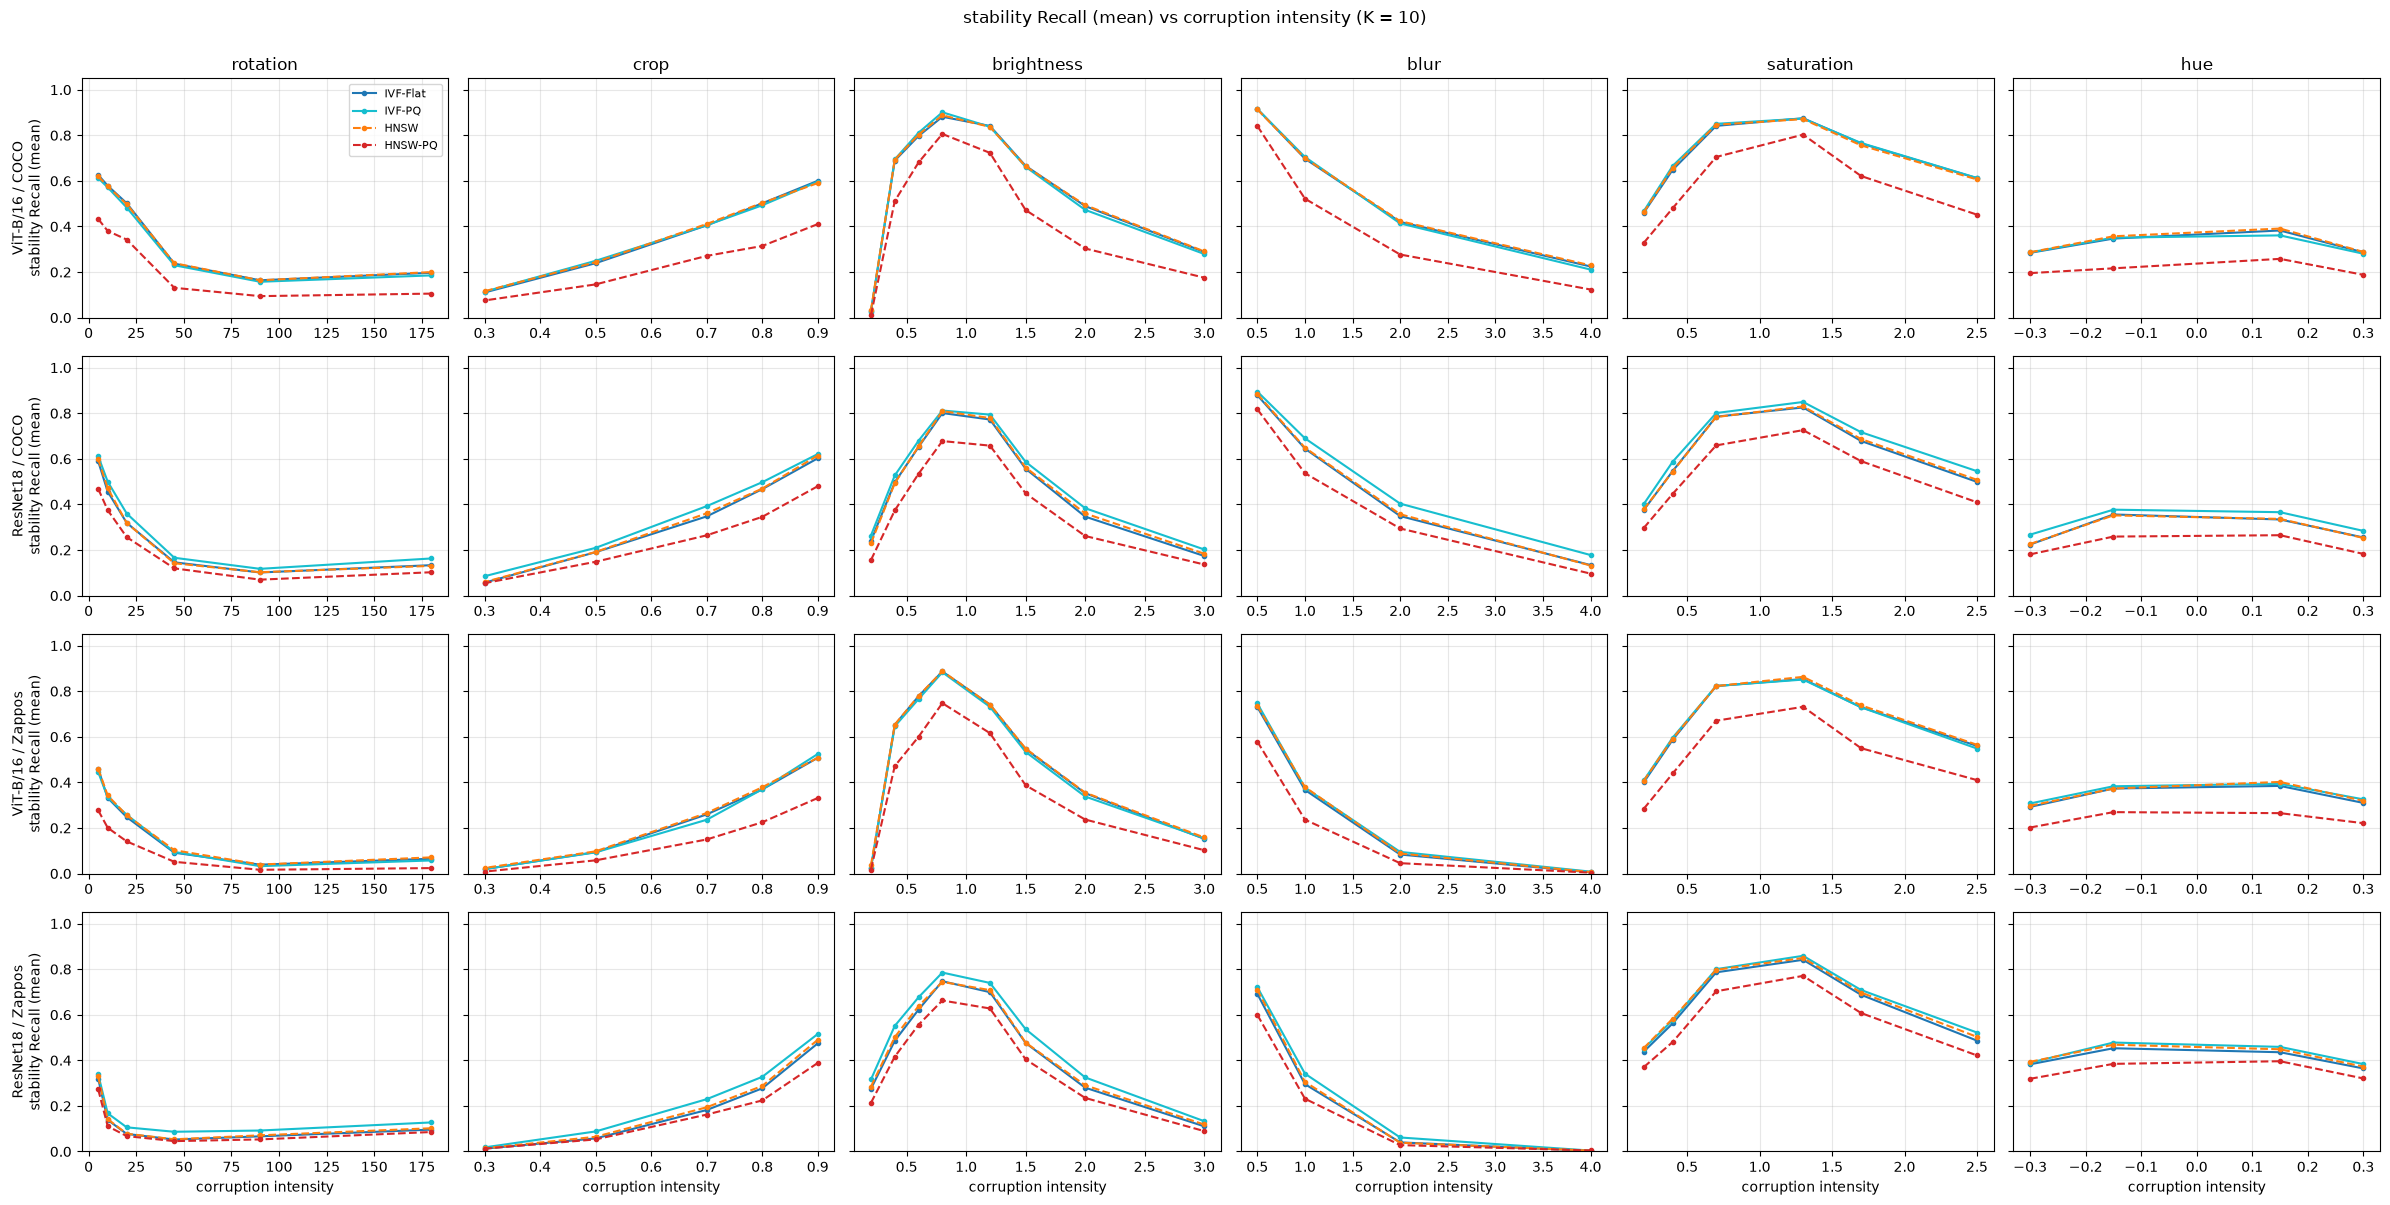

In [5]:
corruption_grid(f"stability_recall_at_{K_SHOW}_mean", "stability Recall (mean)")

## 5. ANN-induced additional loss

Exact end-to-end minus index end-to-end at K = 10: how much retrieval
quality each index loses **on top of** the model's corruption loss. Negative
values (blue) mean the index accidentally agreed more with the clean ground
truth than exact search on the corrupted query did.

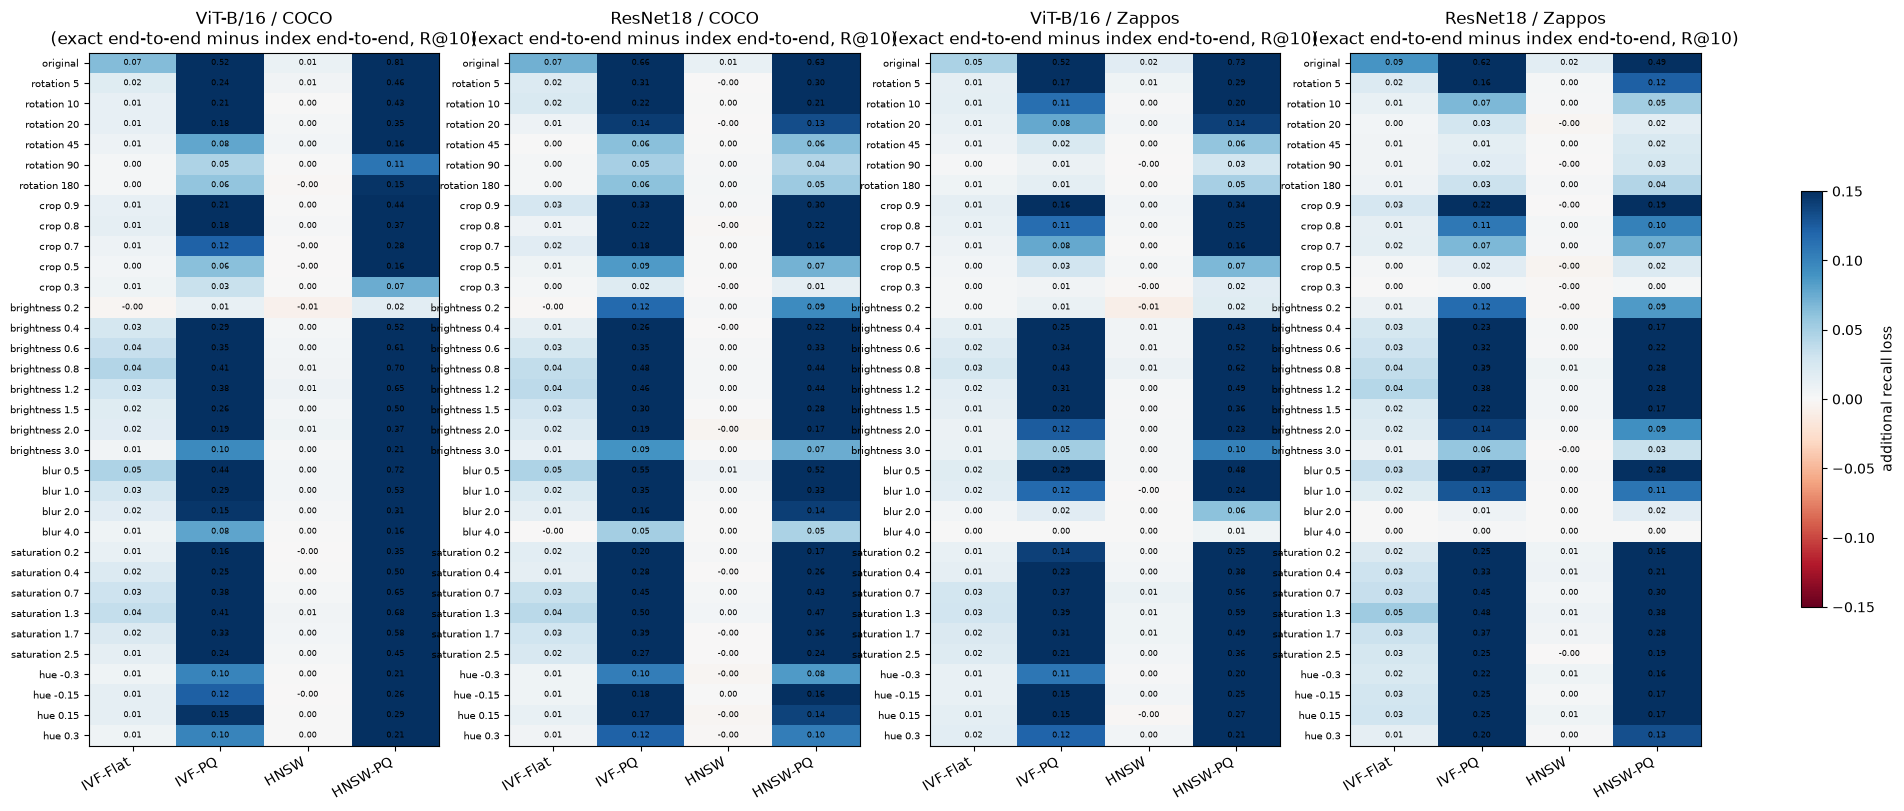

In [6]:
def exact_reference(key, transform, level):
    row = exact[(exact["config"] == key) & (exact["transform"] == transform)
                & (exact["level"] == level)]
    return float(row[f"recall_at_{K_SHOW}_mean"].iloc[0]) if len(row) else np.nan

fig, axes = plt.subplots(1, len(CONFIG_KEYS),
                         figsize=(6.5 * len(CONFIG_KEYS), 9))
for ax, key in zip(axes, CONFIG_KEYS):
    rows = summary[summary["config"] == key]
    variants = (rows[rows["algorithm"] == ALGORITHMS[0]]
                .sort_values("order", kind="stable"))
    labels = [f"{t} {l}" if t != "original" else "original"
              for t, l in zip(variants["transform"], variants["level"])]
    grid = np.full((len(variants), len(ALGORITHMS)), np.nan)
    for i, (_, variant) in enumerate(variants.iterrows()):
        if exact is None:
            continue
        reference = exact_reference(key, variant["transform"], variant["level"])
        for j, algorithm in enumerate(ALGORITHMS):
            match = rows[(rows["algorithm"] == algorithm)
                         & (rows["transform"] == variant["transform"])
                         & (rows["level"] == variant["level"])]
            grid[i, j] = reference - float(match[f"end_to_end_recall_at_{K_SHOW}_mean"].iloc[0])
    image = ax.imshow(grid, cmap="RdBu", vmin=-0.15, vmax=0.15, aspect="auto")
    ax.set_xticks(range(len(ALGORITHMS)), ALGORITHMS, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.set_title(f"{CONFIGS[key]['label']}\n(exact end-to-end minus index end-to-end, R@{K_SHOW})")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            if np.isfinite(grid[i, j]):
                ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(image, ax=axes, shrink=0.6, label="additional recall loss")
plt.show()

## 6. Sanity checks

- `original` level: stability exactly 1.0 and fidelity = end-to-end (checked in
  Section 1).
- Every algorithm/level group aggregates the same number of queries.
- The exact reference used here is the corruption experiment's own summary.

In [7]:
checks = []
for key in CONFIG_KEYS:
    rows = summary[summary["config"] == key]
    for algorithm in ALGORITHMS:
        algo = rows[rows["algorithm"] == algorithm]
        counts = algo.groupby("transform", sort=False).size()
        checks.append({
            "config": key, "algorithm": algorithm,
            "groups": len(algo),
            "queries_per_group": sorted(counts.unique().tolist()),
            "transforms": sorted(algo["transform"].unique().tolist()),
        })
display(pd.DataFrame(checks))

if exact is not None:
    for key in CONFIG_KEYS:
        original = exact[(exact["config"] == key) & (exact["transform"] == "original")]
        assert len(original) == 1
        value = float(original[f"recall_at_{K_SHOW}_mean"].iloc[0])
        # Re-embedding the original image can flip near-tied neighbours, so the
        # original level is not always exactly 1.0 (e.g. 0.9995 for ResNet).
        assert value >= 0.995, (key, value)
    print(f"exact corruption reference: original recall@{K_SHOW} >= 0.995 in every configuration")

,config,algorithm,groups,queries_per_group,transforms
0,vit-coco,IVF-Flat,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
1,vit-coco,IVF-PQ,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
2,vit-coco,HNSW,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
3,vit-coco,HNSW-PQ,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
4,resnet-coco,IVF-Flat,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
5,resnet-coco,IVF-PQ,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
6,resnet-coco,HNSW,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
7,resnet-coco,HNSW-PQ,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
8,vit-zappos,IVF-Flat,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."
9,vit-zappos,IVF-PQ,34,"[1, 4, 5, 6, 8]","[blur, brightness, crop, hue, original, rotati..."


exact corruption reference: original recall@10 >= 0.995 in every configuration


## How to adjust

- `K_SHOW` (first cell) changes K in every plot (5/10/20 are available).
- `CONFIG_KEYS` reorders or subsets configurations.
- Per-variant rows and per-method neighbour arrays are in
  `results/<config>/index_robustness/per_query/` (local only, git-ignored) if
  you want distributions or example grids.
- Rerun the experiment with:
  `python experiments/ann-comparison/pipeline/index_robustness.py --config all`